# Class 15 — Encoding and Embedding: Titanic Solution

Worked solution to the [Class 15 activity](../documents/Class15_Encoding_Embedding_Activity.md). Section numbers follow the activity steps. No predictive model is trained, so nothing here shows that an encoding improves prediction.

## Setup
Libraries and the prepared CSV (891 rows, all used).

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import chi2_contingency, spearmanr
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

df = pd.read_csv("Class15_Titanic_Imputed.csv")
print(df.shape)
df.head()

(891, 8)


,sex,pclass,embarked,age,fare,sibsp,parch,survived
0,male,3,S,22.0,7.2500,1.0,0.0,0
1,female,1,C,38.0,71.2833,1.0,0.0,1
2,female,3,S,26.0,7.9250,0.0,0.0,1
3,female,1,S,35.0,53.1000,1.0,0.0,1
4,male,3,S,35.0,8.0500,0.0,0.0,0


## 1. Choose a representation
`sex` and `embarked` are nominal: one-hot. `pclass` is ordered: compare one-hot with ordinal codes 1, 2, 3. Ordinal codes assume equal steps between classes.

## 2. Inspect the encoded matrix

In [2]:
nominal = ["sex", "embarked"]
# handle_unknown="ignore": unseen category -> all zeros instead of an error
# sparse_output=False: return a dense numpy array instead of a sparse matrix
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
X_nominal = ohe.fit_transform(df[nominal])

print(ohe.categories_)
print(ohe.get_feature_names_out(nominal))
print("shape:", X_nominal.shape)
print("density:", np.count_nonzero(X_nominal) / X_nominal.size)

[array(['female', 'male'], dtype=object), array(['C', 'Q', 'S'], dtype=object)]
['sex_female' 'sex_male' 'embarked_C' 'embarked_Q' 'embarked_S']
shape: (891, 5)
density: 0.4


In [3]:
# Unseen port: the embarked block becomes all zeros, no error.
unseen = pd.DataFrame({"sex": ["female"], "embarked": ["NEW_PORT"]})
print(ohe.transform(unseen))

[[1. 0. 0. 0. 0.]]


In [4]:
# categories: explicit order of levels, so codes follow 1 < 2 < 3
pclass_onehot = OneHotEncoder(sparse_output=False).fit(df[["pclass"]])
pclass_ordinal = OrdinalEncoder(categories=[[1, 2, 3]]).fit(df[["pclass"]])

print("one-hot columns:", pclass_onehot.get_feature_names_out(["pclass"]))
print("one-hot shape:", pclass_onehot.transform(df[["pclass"]]).shape)
print("ordinal shape:", pclass_ordinal.transform(df[["pclass"]]).shape)

one-hot columns: ['pclass_1' 'pclass_2' 'pclass_3']
one-hot shape: (891, 3)
ordinal shape: (891, 1)


## 3. Explore association with survival

In [5]:
for col in ["embarked", "pclass"]:
    # agg(name=(column, function)): count = group size, mean of 0/1 = survival rate
    print(df.groupby(col)["survived"].agg(passengers="count", survival_rate="mean").round(3), "\n")

          passengers  survival_rate
embarked                           
C                168          0.554
Q                 77          0.390
S                646          0.339 

        passengers  survival_rate
pclass                           
1              216          0.630
2              184          0.473
3              491          0.242 



In [6]:
# crosstab: counts table; correction=False: no Yates continuity correction
# returns statistic, p-value, degrees of freedom, expected counts
chi2, p, dof, _ = chi2_contingency(pd.crosstab(df["embarked"], df["survived"]), correction=False)
print(f"chi-square={chi2:.2f}, df={dof}, p-value={p:.4g}")

rho, p = spearmanr(df["fare"], df["survived"])
print(f"Spearman rho={rho:.2f}, p-value={p:.4g}")

chi-square=25.96, df=2, p-value=2.301e-06
Spearman rho=0.32, p-value=3.471e-23


Heatmaps: Spearman among numeric features and target; chi-squared p-values among categorical pairs. The panels use different scales, so do not compare their colors. A small p-value is not an effect size.

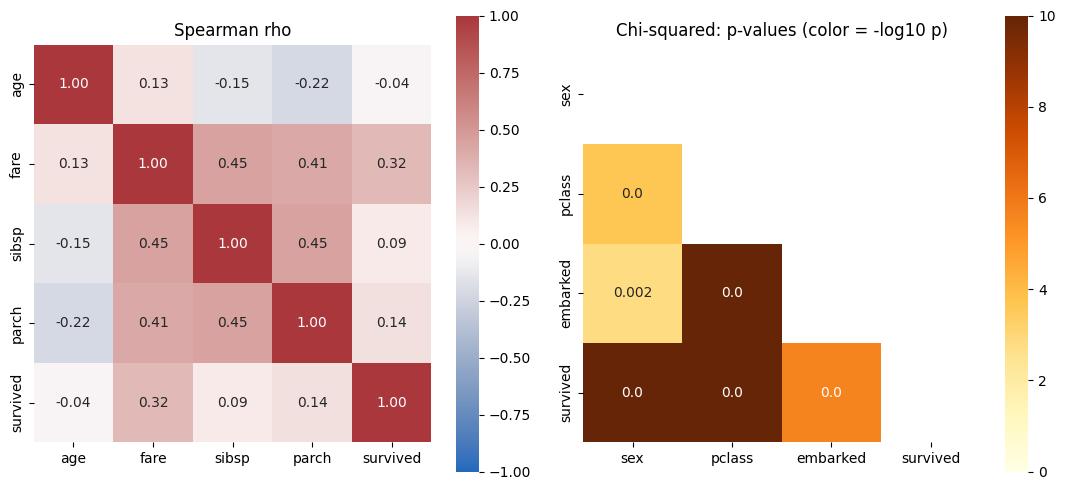

In [7]:
# method="spearman": rank correlation instead of Pearson
spearman = df[["age", "fare", "sibsp", "parch", "survived"]].corr(method="spearman")

cats = ["sex", "pclass", "embarked", "survived"]
pvals = pd.DataFrame(np.nan, index=cats, columns=cats)
for i, a in enumerate(cats):
    for b in cats[i + 1:]:
        pvals.loc[a, b] = pvals.loc[b, a] = chi2_contingency(pd.crosstab(df[a], df[b]), correction=False)[1]
# -log10(p): larger = stronger evidence against independence; clip avoids log(0) and caps the scale
evidence = -np.log10(pvals.clip(lower=1e-300)).clip(upper=10)

# 1 row x 2 columns of panels; figsize in inches (width, height)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
# annot: write values in cells; fmt: number format; cmap: colors; center/vmin/vmax: fix scale to [-1, 1] around 0
# square: square cells; ax: which subplot to draw on
sns.heatmap(spearman, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title("Spearman rho")
# annot=pvals: show p-values as labels (fmt="" keeps them as given); mask: hide the redundant upper triangle
sns.heatmap(evidence, annot=pvals.round(3), fmt="", cmap="YlOrBr", vmin=0, vmax=10, square=True,
            mask=np.triu(np.ones(len(cats), dtype=bool)), ax=axes[1])
axes[1].set_title("Chi-squared: p-values (color = -log10 p)")
plt.tight_layout()
plt.show()

## 4. PCA projection of port profiles
Profiles use passenger predictors only, never `survived`.

In [8]:
# log1p = log(1 + x): tames the skewed fare and is safe at 0
df["log_fare"] = np.log1p(df["fare"])
df["family_size"] = df["sibsp"] + df["parch"] + 1
df["is_female"] = (df["sex"] == "female").astype(int)

# agg(name=(column, function)): one row per port, one summary column per profile feature
profile = df.groupby("embarked").agg(
    mean_age=("age", "mean"),
    mean_log_fare=("log_fare", "mean"),
    mean_pclass=("pclass", "mean"),
    mean_family_size=("family_size", "mean"),
    female_share=("is_female", "mean"),
)
profile

,mean_age,mean_log_fare,mean_pclass,mean_family_size,female_share
embarked,,,,,
C,30.178095,3.489332,1.886905,1.750000,0.434524
Q,28.032468,2.456975,2.909091,1.597403,0.467532
S,29.307663,2.885396,2.346749,1.981424,0.317337


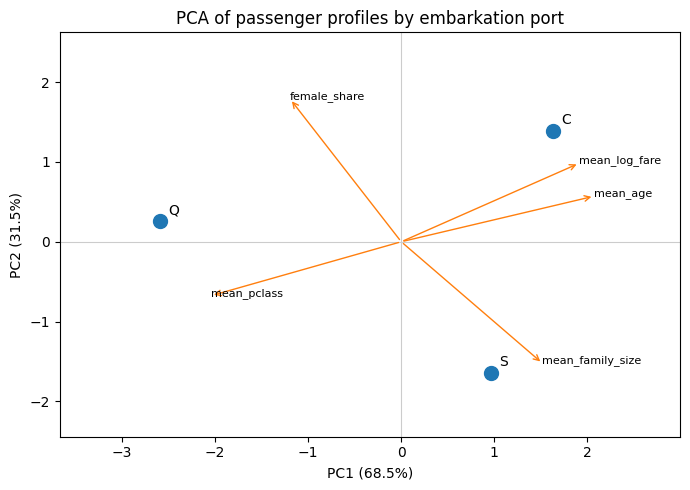

Variance explained: 1.0


,PC1,PC2
mean_age,0.964,0.266
mean_log_fare,0.889,0.458
mean_pclass,-0.949,-0.314
mean_family_size,0.706,-0.709
female_share,-0.555,0.832


In [9]:
scaled = StandardScaler().fit_transform(profile)
# StandardScaler: zero mean, unit variance per column (features have different scales)
# n_components=2: keep the first two principal components
pca = PCA(n_components=2)
xy = pca.fit_transform(scaled)

# Correlation of each original feature with PC1 and PC2, drawn as arrows (rescaled for display).
corr = pd.DataFrame(np.corrcoef(scaled.T, xy.T)[:5, 5:], index=profile.columns, columns=["PC1", "PC2"])
# np.corrcoef rows/cols: 5 features then 2 PCs; keep the feature-vs-PC block
scale = 0.8 * np.abs(xy).max() / np.abs(corr.to_numpy()).max()

fig, ax = plt.subplots(figsize=(7, 5))
# s: marker size; xytext/textcoords: label offset in points from the marker
ax.scatter(xy[:, 0], xy[:, 1], s=100)
for port, (x, y) in zip(profile.index, xy):
    ax.annotate(port, (x, y), xytext=(6, 5), textcoords="offset points")
for name, (x, y) in (corr * scale).iterrows():
    # empty text + arrowprops draws an arrow from xytext (origin) to xy
    ax.annotate("", xy=(x, y), xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": "tab:orange"})
    ax.text(x, y, name, fontsize=8)
# annotate does not rescale the axes: fit the limits to points and arrows, with margin for labels
ends = np.vstack([xy, corr.to_numpy() * scale])
ax.set_xlim(ends[:, 0].min() * 1.3 - 0.3, ends[:, 0].max() * 1.3 + 0.3)
ax.set_ylim(ends[:, 1].min() * 1.3 - 0.3, ends[:, 1].max() * 1.3 + 0.3)
ax.axhline(0, color="0.8", linewidth=0.8)
ax.axvline(0, color="0.8", linewidth=0.8)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("PCA of passenger profiles by embarkation port")
plt.tight_layout()
plt.show()

print("Variance explained:", pca.explained_variance_ratio_.sum())
corr.round(3)

Three centered profiles have rank at most 2, so two PCs explain 100% by construction. PCA on the three one-hot port columns has the same limit and only rotates the same information.

## 5. What the evidence supports

**Supported now:** the representation keeps the observed categories, has a known size and density, handles unseen ports with documented behavior, and the data show descriptive group differences.

**Not supported yet:** that one-hot or any embedding improves a model. Class 18 tests that with a train/test split from raw data, a fixed estimator and metric, and preprocessing fitted on training data only.